In [ ]:

import os
from google.colab import files

print("Please upload your kaggle.json file:")
uploaded = files.upload()

if "kaggle.json" not in uploaded:
    raise FileNotFoundError("upload kaggle.json ")

# تنظیم دسترسی‌ها برای Kaggle API
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json
print("Kaggle API token configured successfully!")

# ایجاد پوشه، دانلود و استخراج دیتاست Potsdam/Vaihingen
!mkdir -p /content/dataset
!kaggle datasets download -d bkfateam/potsdamvaihingen -p /content/dataset
!unzip -q /content/dataset/potsdamvaihingen.zip -d /content/dataset/PotsdamVaihingen
!rm /content/dataset/potsdamvaihingen.zip

print("Dataset downloaded and extracted to /content/dataset/PotsdamVaihingen successfully!")

Please upload your kaggle.json file:


Saving kaggle.json to kaggle.json
Kaggle API token configured successfully!
Dataset URL: https://www.kaggle.com/datasets/bkfateam/potsdamvaihingen
License(s): DbCL-1.0
100% 13.9G/13.9G [02:42<00:00, 92.0MB/s]

Dataset downloaded and extracted to /content/dataset/PotsdamVaihingen successfully!


In [ ]:

import os
import glob
import cv2
import numpy as np
from tqdm import tqdm
from typing import Dict, Tuple, List


DATASET_CHOICE: str = 'Vaihingen'
PATCH_SIZE: int = 512
STRIDE: int = 512  


ISPRS_COLOR_MAP: Dict[Tuple[int, int, int], int] = {
    (255, 255, 255): 0,  # Impervious surfaces (White)
    (0, 0, 255): 1,      # Building (Blue)
    (0, 255, 255): 2,    # Low vegetation (Cyan)
    (0, 255, 0): 3,      # Tree (Green)
    (255, 255, 0): 4,    # Car (Yellow)
    (255, 0, 0): 5       # Clutter / Background (Red)
}

def rgb_to_2d_label(mask_rgb: np.ndarray) -> np.ndarray:
  
    if mask_rgb.ndim == 2:
        return mask_rgb.astype(np.uint8)

    mask_2d = np.zeros((mask_rgb.shape[0], mask_rgb.shape[1]), dtype=np.uint8)
    for rgb, class_idx in ISPRS_COLOR_MAP.items():
        matches = np.all(mask_rgb == rgb, axis=-1)
        mask_2d[matches] = class_idx
    return mask_2d

def prepare_patches(dataset_name: str, base_raw_dir: str, output_dir: str) -> None:
  
    if os.path.exists(output_dir) and len(os.listdir(os.path.join(output_dir, 'train', 'images'))) > 0:
        print(f"✅")
        return

    for split in ['train', 'val']:
        os.makedirs(os.path.join(output_dir, split, 'images'), exist_ok=True)
        os.makedirs(os.path.join(output_dir, split, 'masks'), exist_ok=True)

    pairs: List[Tuple[str, str]] = []

    if dataset_name == 'Vaihingen':
        gt_dir = os.path.join(base_raw_dir, 'ISPRS_semantic_labeling_Vaihingen', 'gts_for_participants')
        img_dir = os.path.join(base_raw_dir, 'ISPRS_semantic_labeling_Vaihingen', 'top')
        gt_files = sorted(glob.glob(os.path.join(gt_dir, '*.tif')))
        for gt_path in gt_files:
            fname = os.path.basename(gt_path)
            img_path = os.path.join(img_dir, fname)
            if os.path.exists(img_path):
                pairs.append((img_path, gt_path))

    elif dataset_name == 'Potsdam':
        gt_dir = os.path.join(base_raw_dir, '5_Labels_for_participants', '5_Labels_for_participants')
        img_dir = os.path.join(base_raw_dir, '3_Ortho_IRRG', '3_Ortho_IRRG')
        gt_files = sorted(glob.glob(os.path.join(gt_dir, '*_label.tif')))
        for gt_path in gt_files:
            fname = os.path.basename(gt_path)
            
            img_fname = fname.replace('_label.tif', '_IRRG.tif')
            img_path = os.path.join(img_dir, img_fname)
            if os.path.exists(img_path):
                pairs.append((img_path, gt_path))

    
    split_idx = int(len(pairs) * 0.8)
    train_pairs = pairs[:split_idx]
    val_pairs = pairs[split_idx:]

    print(f"⏳")

    for split_name, split_pairs in [('train', train_pairs), ('val', val_pairs)]:
        patch_count = 0
        for img_path, gt_path in tqdm(split_pairs, desc=f"Processing {split_name}"):
            
            img_bgr = cv2.imread(img_path, cv2.IMREAD_COLOR)
            img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

           
            gt_raw = cv2.imread(gt_path, cv2.IMREAD_UNCHANGED)
            if gt_raw.ndim == 3:
                gt_rgb = cv2.cvtColor(gt_raw, cv2.COLOR_BGR2RGB)
                mask_2d = rgb_to_2d_label(gt_rgb)
            else:
                mask_2d = gt_raw.astype(np.uint8)

            h, w, _ = img_rgb.shape
            base_name = os.path.splitext(os.path.basename(img_path))[0]

            
            for y in range(0, h - PATCH_SIZE + 1, STRIDE):
                for x in range(0, w - PATCH_SIZE + 1, STRIDE):
                    img_patch = img_rgb[y:y+PATCH_SIZE, x:x+PATCH_SIZE]
                    mask_patch = mask_2d[y:y+PATCH_SIZE, x:x+PATCH_SIZE]

                    patch_filename = f"{base_name}_y{y}_x{x}.png"
                    
                    cv2.imwrite(
                        os.path.join(output_dir, split_name, 'images', patch_filename),
                        cv2.cvtColor(img_patch, cv2.COLOR_RGB2BGR)
                    )
                    
                    cv2.imwrite(
                        os.path.join(output_dir, split_name, 'masks', patch_filename),
                        mask_patch
                    )
                    patch_count += 1
        print(f"✔️")

RAW_DATASET_DIR = '/content/dataset/PotsdamVaihingen'
PROCESSED_DATA_DIR = f'/content/dataset/processed_{DATASET_CHOICE}'
prepare_patches(DATASET_CHOICE, RAW_DATASET_DIR, PROCESSED_DATA_DIR)

In [ ]:

import glob
from typing import List, Dict, Optional, Callable
import cv2
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader
import albumentations as A
from albumentations.pytorch import ToTensorV2


device: str = "cuda" if torch.cuda.is_available() else "cpu"
print(f"🚀 Running on device: {device}")

def get_train_transforms(crop_size: int = 512) -> A.Compose:

    return A.Compose([
        
        A.RandomScale(scale_limit=(-0.5, 0.5), p=1.0),


        A.PadIfNeeded(min_height=crop_size, min_width=crop_size, border_mode=cv2.BORDER_CONSTANT, value=0, mask_value=0),

       
        A.RandomCrop(height=crop_size, width=crop_size, p=1.0),

        
        A.HorizontalFlip(p=0.5),
        A.VerticalFlip(p=0.5),
        A.RandomRotate90(p=0.5),

        
        A.Normalize(
            mean=(0.485, 0.456, 0.406),
            std=(0.229, 0.224, 0.225),
            max_pixel_value=255.0
        ),

       
        ToTensorV2()
    ])


def get_val_transforms(crop_size: int = 512) -> A.Compose:

    return A.Compose([
        A.Resize(height=crop_size, width=crop_size),
        A.Normalize(
            mean=(0.485, 0.456, 0.406),
            std=(0.229, 0.224, 0.225),
            max_pixel_value=255.0
        ),
        ToTensorV2()
    ])


class ISPRSSegmentationDataset(Dataset):

    def __init__(
        self,
        image_paths: List[str],
        mask_paths: List[str],
        transform: Optional[Callable] = None
    ) -> None:

        super().__init__()
        assert len(image_paths) == len(mask_paths), "same masks"
        self.image_paths: List[str] = image_paths
        self.mask_paths: List[str] = mask_paths
        self.transform: Optional[Callable] = transform

    def __len__(self) -> int:
  
        return len(self.image_paths)

    def __getitem__(self, idx: int) -> Dict[str, torch.Tensor]:
        img_path = self.image_paths[idx]
        mask_path = self.mask_paths[idx]

        image = cv2.imread(img_path, cv2.IMREAD_COLOR)
        if image is None:
            raise ValueError(f" {img_path}")
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)  # Shape: [H, W, 3], dtype: uint8

        mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)  # Shape: [H, W], dtype: uint8
        if mask is None:
            raise ValueError(f"{mask_path}")

        
        if self.transform is not None:
            augmented = self.transform(image=image, mask=mask)
            image_tensor = augmented['image']  # Shape: [3, H, W]
            mask_tensor = augmented['mask']    # Shape: [H, W]
        else:
            
            image_tensor = torch.from_numpy(image.transpose(2, 0, 1)).float() / 255.0  # Shape: [3, H, W]
            mask_tensor = torch.from_numpy(mask)                                       # Shape: [H, W]

       
        image_tensor = image_tensor.to(dtype=torch.float32)  # Shape: [3, H, W], dtype: torch.float32
        mask_tensor = mask_tensor.to(dtype=torch.int64)      # Shape: [H, W], dtype: torch.int64 (long)

        return {
            'image': image_tensor,  # Shape: [3, H, W], dtype: torch.float32
            'mask': mask_tensor     # Shape: [H, W], dtype: torch.int64
        }

🚀 Running on device: cuda


In [ ]:

import os
import glob


train_image_paths: List[str] = sorted(glob.glob(os.path.join(PROCESSED_DATA_DIR, 'train', 'images', '*.png')))
train_mask_paths: List[str] = sorted(glob.glob(os.path.join(PROCESSED_DATA_DIR, 'train', 'masks', '*.png')))

val_image_paths: List[str] = sorted(glob.glob(os.path.join(PROCESSED_DATA_DIR, 'val', 'images', '*.png')))
val_mask_paths: List[str] = sorted(glob.glob(os.path.join(PROCESSED_DATA_DIR, 'val', 'masks', '*.png')))

print(f"📊Train: {len(train_image_paths)} | Val: {len(val_image_paths)}")


train_dataset = ISPRSSegmentationDataset(
    image_paths=train_image_paths,
    mask_paths=train_mask_paths,
    transform=get_train_transforms(crop_size=512)
)

val_dataset = ISPRSSegmentationDataset(
    image_paths=val_image_paths,
    mask_paths=val_mask_paths,
    transform=get_val_transforms(crop_size=512)
)


BATCH_SIZE: int = 16
NUM_WORKERS: int = 2 if os.cpu_count() is not None and os.cpu_count() < 4 else 4

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    drop_last=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    drop_last=False
)


sample_batch = next(iter(train_loader))
images_batch: torch.Tensor = sample_batch['image']  # Expected Shape: [16, 3, 512, 512]
masks_batch: torch.Tensor = sample_batch['mask']    # Expected Shape: [16, 512, 512]

print("\n" + "="*65)
print("🔍 (Module 1 Shape Contract Check):")
print("="*65)
print(f"🖼️ Image Batch Shape : {list(images_batch.shape)} | Expected: [16, 3, 512, 512]")
print(f"🖼️ Image Batch Dtype : {images_batch.dtype}       | Expected: torch.float32")
print(f"🖼️ Image Value Range : [{images_batch.min():.2f}, {images_batch.max():.2f}] | Expected: Normalized (~[-2.1, +2.6])")
print("-" * 65)
print(f"🎭 Mask Batch Shape  : {list(masks_batch.shape)}    | Expected: [16, 512, 512]")
print(f"🎭 Mask Batch Dtype  : {masks_batch.dtype}         | Expected: torch.int64")
print(f"🎭 Unique Class IDs  : {torch.unique(masks_batch).tolist()} | Expected subset of: [0, 1, 2, 3, 4, 5]")
print("="*65)

assert images_batch.shape == (BATCH_SIZE, 3, 512, 512), "❌"
assert images_batch.dtype == torch.float32, "❌"
assert masks_batch.shape == (BATCH_SIZE, 512, 512), "❌ "
assert masks_batch.dtype == torch.int64, "❌"



In [ ]:

from typing import Tuple, Union
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision.models import resnet18, ResNet18_Weights


class ResNet18Encoder(nn.Module):
    """
    Pre-trained ResNet18 backbone extracting 4 multi-scale feature maps
    and projecting all stage channels to a unified decoder dimension (C=64).
    """
    def __init__(self, out_channels: int = 64, pretrained: bool = True) -> None:
        super().__init__()
        weights = ResNet18_Weights.DEFAULT if pretrained else None
        backbone = resnet18(weights=weights)

        # Initial stem layers (downsamples by 4x overall)
        self.stem = nn.Sequential(
            backbone.conv1,      # Stride 2 -> H/2, W/2
            backbone.bn1,
            backbone.relu,
            backbone.maxpool     # Stride 2 -> H/4, W/4
        )

        # 4 Hierarchical ResNet Stages
        self.stage1 = backbone.layer1  # Channels: 64,  Scale: 1/4
        self.stage2 = backbone.layer2  # Channels: 128, Scale: 1/8
        self.stage3 = backbone.layer3  # Channels: 256, Scale: 1/16
        self.stage4 = backbone.layer4  # Channels: 512, Scale: 1/32

        # 1x1 Convolutions for channel reduction to 64
        self.conv_c1 = nn.Conv2d(64, out_channels, kernel_size=1, stride=1, padding=0)
        self.conv_c2 = nn.Conv2d(128, out_channels, kernel_size=1, stride=1, padding=0)
        self.conv_c3 = nn.Conv2d(256, out_channels, kernel_size=1, stride=1, padding=0)
        self.conv_c4 = nn.Conv2d(512, out_channels, kernel_size=1, stride=1, padding=0)

    def forward(self, x: torch.Tensor) -> Tuple[torch.Tensor, torch.Tensor, torch.Tensor, torch.Tensor]:
        """
        Forward pass through ResNet18 stages and 1x1 channel projections.

        Args:
            x (torch.Tensor): Input image tensor of shape [B, 3, H, W].

        Returns:
            Tuple of 4 tensors (c1, c2, c3, c4) reduced to 64 channels.
        """
        x_stem = self.stem(x)          # Shape: [B, 64, H/4, W/4]

        s1 = self.stage1(x_stem)       # Shape: [B, 64, H/4, W/4]
        s2 = self.stage2(s1)           # Shape: [B, 128, H/8, W/8]
        s3 = self.stage3(s2)           # Shape: [B, 256, H/16, W/16]
        s4 = self.stage4(s3)           # Shape: [B, 512, H/32, W/32]

        c1 = self.conv_c1(s1)          # Shape: [B, 64, H/4, W/4]
        c2 = self.conv_c2(s2)          # Shape: [B, 64, H/8, W/8]
        c3 = self.conv_c3(s3)          # Shape: [B, 64, H/16, W/16]
        c4 = self.conv_c4(s4)          # Shape: [B, 64, H/32, W/32]

        return c1, c2, c3, c4


class WeightedSum(nn.Module):
    """
    Learnable weighted sum fusion module for combining encoder skip connections
    and upsampled decoder features: F = alpha * enc_feat + (1 - alpha) * dec_feat.
    """
    def __init__(self, init_alpha: float = 0.5) -> None:
        super().__init__()
        self.alpha = nn.Parameter(torch.tensor(init_alpha, dtype=torch.float32))

    def forward(self, enc_feat: torch.Tensor, dec_feat: torch.Tensor) -> torch.Tensor:
        """
        Args:
            enc_feat (torch.Tensor): Encoder feature tensor of shape [B, C, H, W].
            dec_feat (torch.Tensor): Decoder feature tensor of shape [B, C, H, W].

        Returns:
            torch.Tensor: Fused feature tensor of shape [B, C, H, W].
        """
        fused = self.alpha * enc_feat + (1.0 - self.alpha) * dec_feat  # Shape: [B, C, H, W]
        return fused

In [ ]:

import torch
import torch.nn as nn
import torch.nn.functional as F


class CrossShapedWindowInteraction(nn.Module):
    """
    Cross-shaped Window Context Interaction module capturing horizontal and vertical
    cross-window dependencies via directional average pooling.
    """
    def __init__(self, dim: int = 64, window_size: int = 8) -> None:
        super().__init__()
        self.window_size = window_size
        self.proj_h = nn.Sequential(
            nn.Conv2d(dim, dim, kernel_size=1, stride=1, padding=0),
            nn.BatchNorm2d(dim)
        )
        self.proj_w = nn.Sequential(
            nn.Conv2d(dim, dim, kernel_size=1, stride=1, padding=0),
            nn.BatchNorm2d(dim)
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """
        Args:
            x (torch.Tensor): Window-attended feature map of shape [B, C, H, W].

        Returns:
            torch.Tensor: Context-interacted global feature map of shape [B, C, H, W].
        """
        B, C, H, W = x.shape
        w = self.window_size

        # Horizontal pooling to (H // w, W) and upsampling back to (H, W)
        pool_h = F.adaptive_avg_pool2d(x, (max(1, H // w), W))              # Shape: [B, C, H/w, W]
        ctx_h = self.proj_h(pool_h)                                         # Shape: [B, C, H/w, W]
        ctx_h = F.interpolate(ctx_h, size=(H, W), mode='bilinear', align_corners=True)  # Shape: [B, C, H, W]

        # Vertical pooling to (H, W // w) and upsampling back to (H, W)
        pool_w = F.adaptive_avg_pool2d(x, (H, max(1, W // w)))              # Shape: [B, C, H, W/w]
        ctx_w = self.proj_w(pool_w)                                         # Shape: [B, C, H, W/w]
        ctx_w = F.interpolate(ctx_w, size=(H, W), mode='bilinear', align_corners=True)  # Shape: [B, C, H, W]

        # Fuse horizontal and vertical contexts onto the window attention output
        out = x + ctx_h + ctx_w                                             # Shape: [B, C, H, W]
        return out


class EfficientGlobalLocalAttention(nn.Module):
    """
    Efficient Global-Local Attention (EGLA) combining parallel 3x3 and 1x1 local convolutions
    with Window-based Multi-Head Self-Attention and Cross-Shaped Window Interaction.
    """
    def __init__(self, dim: int = 64, num_heads: int = 8, window_size: int = 8) -> None:
        super().__init__()
        assert dim % num_heads == 0, "dim must be divisible by num_heads."
        self.dim = dim
        self.num_heads = num_heads
        self.window_size = window_size
        self.head_dim = dim // num_heads
        self.scale = self.head_dim ** -0.5

        # 1. Local Branch: parallel 3x3 and 1x1 convolutions with BatchNorm
        self.local_conv3x3 = nn.Sequential(
            nn.Conv2d(dim, dim, kernel_size=3, stride=1, padding=1, bias=False),
            nn.BatchNorm2d(dim)
        )
        self.local_conv1x1 = nn.Sequential(
            nn.Conv2d(dim, dim, kernel_size=1, stride=1, padding=0, bias=False),
            nn.BatchNorm2d(dim)
        )

        # 2. Global Branch: 1x1 Conv to 3*C (192) for Q, K, V
        self.qkv_conv = nn.Conv2d(dim, dim * 3, kernel_size=1, stride=1, padding=0)

        # Relative Position Bias Table for window size w x w
        self.relative_position_bias_table = nn.Parameter(
            torch.zeros((2 * window_size - 1) * (2 * window_size - 1), num_heads)
        )
        nn.init.trunc_normal_(self.relative_position_bias_table, std=0.02)

        # Compute pairwise relative position index for an 8x8 window
        coords_h = torch.arange(self.window_size)
        coords_w = torch.arange(self.window_size)
        coords = torch.stack(torch.meshgrid([coords_h, coords_w], indexing='ij'))  # Shape: [2, w, w]
        coords_flatten = torch.flatten(coords, 1)                                  # Shape: [2, w*w]
        relative_coords = coords_flatten[:, :, None] - coords_flatten[:, None, :]  # Shape: [2, w*w, w*w]
        relative_coords = relative_coords.permute(1, 2, 0).contiguous()            # Shape: [w*w, w*w, 2]
        relative_coords[:, :, 0] += self.window_size - 1
        relative_coords[:, :, 1] += self.window_size - 1
        relative_coords[:, :, 0] *= 2 * self.window_size - 1
        relative_position_index = relative_coords.sum(-1)                          # Shape: [w*w, w*w]
        self.register_buffer("relative_position_index", relative_position_index)

        # Cross-Shaped Window Context Interaction
        self.cross_window_interaction = CrossShapedWindowInteraction(dim=dim, window_size=window_size)

        # 3. Fusion & Post-processing: Depthwise 3x3 -> BN -> Conv 1x1
        self.post_conv = nn.Sequential(
            nn.Conv2d(dim, dim, kernel_size=3, stride=1, padding=1, groups=dim, bias=False),
            nn.BatchNorm2d(dim),
            nn.Conv2d(dim, dim, kernel_size=1, stride=1, padding=0)
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """
        Args:
            x (torch.Tensor): Normalized feature tensor of shape [B, 64, H, W].

        Returns:
            torch.Tensor: Output feature tensor of shape [B, 64, H, W].
        """
        B, C, H, W = x.shape
        w = self.window_size

        # ---------------------------------------------------------------------
        # Branch 1: Local Context Extraction
        # ---------------------------------------------------------------------
        local_context = self.local_conv3x3(x) + self.local_conv1x1(x)  # Shape: [B, 64, H, W]

        # ---------------------------------------------------------------------
        # Branch 2: Global Context Extraction (Window Attention + CSWI)
        # ---------------------------------------------------------------------
        # Pad spatial dimensions if not divisible by window_size (8)
        pad_h = (w - H % w) % w
        pad_w = (w - W % w) % w
        x_padded = F.pad(x, (0, pad_w, 0, pad_h)) if (pad_h > 0 or pad_w > 0) else x
        _, _, Hp, Wp = x_padded.shape

        # QKV Projection
        qkv = self.qkv_conv(x_padded)  # Shape: [B, 192, Hp, Wp]

        # Window Partitioning: [B, 192, Hp, Wp] -> [B * N_win, 192, w * w]
        num_win_h, num_win_w = Hp // w, Wp // w
        N_win = num_win_h * num_win_w
        qkv = qkv.view(B, 3 * C, num_win_h, w, num_win_w, w)
        qkv = qkv.permute(0, 2, 4, 1, 3, 5).contiguous()          # Shape: [B, num_win_h, num_win_w, 192, w, w]
        qkv = qkv.view(B * N_win, 3, self.num_heads, self.head_dim, w * w)
        qkv = qkv.permute(1, 0, 2, 4, 3).contiguous()             # Shape: [3, B*N_win, h=8, N_pix=64, d_k=8]

        q, k, v = qkv[0], qkv[1], qkv[2]                          # Each Shape: [B*N_win, 8, 64, 8]

        # Scaled Dot-Product Attention within each 8x8 window
        q = q * self.scale
        attn = (q @ k.transpose(-2, -1))                          # Shape: [B*N_win, 8, 64, 64]

        # Add Relative Position Bias
        rel_pos_bias = self.relative_position_bias_table[self.relative_position_index.view(-1)].view(
            w * w, w * w, -1
        )                                                         # Shape: [64, 64, 8]
        rel_pos_bias = rel_pos_bias.permute(2, 0, 1).contiguous() # Shape: [8, 64, 64]
        attn = attn + rel_pos_bias.unsqueeze(0)                   # Shape: [B*N_win, 8, 64, 64]
        attn = F.softmax(attn, dim=-1)                            # Shape: [B*N_win, 8, 64, 64]

        # Multiply attention weights with V
        win_out = (attn @ v)                                      # Shape: [B*N_win, 8, 64, 8]
        win_out = win_out.transpose(2, 3).contiguous()            # Shape: [B*N_win, 8, 8, 64]
        win_out = win_out.view(B, num_win_h, num_win_w, C, w, w)  # Shape: [B, num_win_h, num_win_w, 64, 8, 8]

        # Window Unpartitioning back to spatial grid
        win_out = win_out.permute(0, 3, 1, 4, 2, 5).contiguous()  # Shape: [B, 64, num_win_h, 8, num_win_w, 8]
        win_out = win_out.view(B, C, Hp, Wp)                      # Shape: [B, 64, Hp, Wp]

        # Remove padding if applied
        if pad_h > 0 or pad_w > 0:
            win_out = win_out[:, :, :H, :W]                       # Shape: [B, 64, H, W]

        # Apply Cross-Shaped Window Context Interaction
        global_context = self.cross_window_interaction(win_out)   # Shape: [B, 64, H, W]

        # ---------------------------------------------------------------------
        # Fusion & Post-Processing
        # ---------------------------------------------------------------------
        fused_context = global_context + local_context            # Shape: [B, 64, H, W]
        out = self.post_conv(fused_context)                       # Shape: [B, 64, H, W]

        return out


class GlobalLocalTransformerBlock(nn.Module):
    """
    Global-Local Transformer Block (GLTB) containing BatchNorm, EGLA,
    residual connections, and a 2-layer Conv1x1 MLP with expansion ratio 4.
    """
    def __init__(self, dim: int = 64, num_heads: int = 8, window_size: int = 8, mlp_ratio: int = 4) -> None:
        super().__init__()
        self.norm1 = nn.BatchNorm2d(dim)
        self.attn = EfficientGlobalLocalAttention(dim=dim, num_heads=num_heads, window_size=window_size)

        self.norm2 = nn.BatchNorm2d(dim)
        hidden_dim = dim * mlp_ratio  # 64 * 4 = 256
        self.mlp = nn.Sequential(
            nn.Conv2d(dim, hidden_dim, kernel_size=1, stride=1, padding=0),
            nn.GELU(),
            nn.Conv2d(hidden_dim, dim, kernel_size=1, stride=1, padding=0)
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """
        Args:
            x (torch.Tensor): Input tensor of shape [B, 64, H, W].

        Returns:
            torch.Tensor: Refined feature tensor of shape [B, 64, H, W].
        """
        # Step 1: Norm1 -> EGLA -> Residual 1
        x_norm1 = self.norm1(x)              # Shape: [B, 64, H, W]
        attn_out = self.attn(x_norm1)        # Shape: [B, 64, H, W]
        x1 = x + attn_out                    # Shape: [B, 64, H, W]

        # Step 2: Norm2 -> MLP -> Residual 2
        x_norm2 = self.norm2(x1)             # Shape: [B, 64, H, W]
        mlp_out = self.mlp(x_norm2)          # Shape: [B, 64, H, W]
        output = x1 + mlp_out                # Shape: [B, 64, H, W]

        return output

In [ ]:

from typing import Union, Tuple
import torch
import torch.nn as nn
import torch.nn.functional as F


class FeatureRefinementHead(nn.Module):
    """
    Feature Refinement Head (FRH) bridging the semantic gap between shallow and deep
    features via parallel Channel and Spatial attention paths before 4x upsampling.
    """
    def __init__(self, in_channels: int = 64, num_classes: int = 6, reduction: int = 4) -> None:
        super().__init__()
        # Initial 3x3 preprocessing convolution
        self.pre_conv = nn.Sequential(
            nn.Conv2d(in_channels, in_channels, kernel_size=3, stride=1, padding=1, bias=False),
            nn.BatchNorm2d(in_channels),
            nn.ReLU(inplace=True)
        )

        # Channel Path: AvgPool(1) -> Conv1x1(64->16) -> ReLU -> Conv1x1(16->64) -> Sigmoid
        reduced_channels = in_channels // reduction  # 64 // 4 = 16
        self.channel_path = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Conv2d(in_channels, reduced_channels, kernel_size=1, stride=1, padding=0),
            nn.ReLU(inplace=True),
            nn.Conv2d(reduced_channels, in_channels, kernel_size=1, stride=1, padding=0),
            nn.Sigmoid()
        )

        # Spatial Path: Depthwise Conv 3x3 -> Sigmoid
        self.spatial_path = nn.Sequential(
            nn.Conv2d(in_channels, in_channels, kernel_size=3, stride=1, padding=1, groups=in_channels),
            nn.Sigmoid()
        )

        # Post-processing after path summation: DWConv 3x3 -> BN -> Conv 1x1
        self.post_conv = nn.Sequential(
            nn.Conv2d(in_channels, in_channels, kernel_size=3, stride=1, padding=1, groups=in_channels, bias=False),
            nn.BatchNorm2d(in_channels),
            nn.Conv2d(in_channels, in_channels, kernel_size=1, stride=1, padding=0)
        )

        # Final classification and 4x upsampling
        self.relu = nn.ReLU(inplace=True)
        self.classifier = nn.Conv2d(in_channels, num_classes, kernel_size=1, stride=1, padding=0)
        self.upsample = nn.Upsample(scale_factor=4, mode='bilinear', align_corners=True)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """
        Args:
            x (torch.Tensor): Fused 1/4 scale feature tensor of shape [B, 64, H/4, W/4].

        Returns:
            torch.Tensor: Full-resolution segmentation logits of shape [B, Num_Classes, H, W].
        """
        feat = self.pre_conv(x)                     # Shape: [B, 64, H/4, W/4]

        # Channel Attention Path
        ch_attn = self.channel_path(feat)           # Shape: [B, 64, 1, 1]
        ch_out = feat * ch_attn                     # Shape: [B, 64, H/4, W/4]

        # Spatial Attention Path
        sp_attn = self.spatial_path(feat)           # Shape: [B, 64, H/4, W/4]
        sp_out = feat * sp_attn                     # Shape: [B, 64, H/4, W/4]

        # Combine paths & apply post-processing + Residual connection
        combined = ch_out + sp_out                  # Shape: [B, 64, H/4, W/4]
        refined = self.post_conv(combined)          # Shape: [B, 64, H/4, W/4]
        res_out = self.relu(feat + refined)         # Shape: [B, 64, H/4, W/4]

        # Classification & 4x Upsampling to original resolution
        logits = self.classifier(res_out)           # Shape: [B, Num_Classes, H/4, W/4]
        out = self.upsample(logits)                 # Shape: [B, Num_Classes, H, W]

        return out


class AuxiliaryHead(nn.Module):
    """
    Auxiliary segmentation head used exclusively during training to supervise
    multi-scale GLTB features from 1/8 resolution.
    """
    def __init__(self, in_channels: int = 64, num_classes: int = 6) -> None:
        super().__init__()
        self.aux_block = nn.Sequential(
            nn.Conv2d(in_channels, in_channels, kernel_size=3, stride=1, padding=1, bias=False),
            nn.BatchNorm2d(in_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(in_channels, num_classes, kernel_size=1, stride=1, padding=0),
            nn.Upsample(scale_factor=8, mode='bilinear', align_corners=True)
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """
        Args:
            x (torch.Tensor): Aggregated GLTB features at 1/8 scale [B, 64, H/8, W/8].

        Returns:
            torch.Tensor: Full-resolution auxiliary logits of shape [B, Num_Classes, H, W].
        """
        out = self.aux_block(x)                     # Shape: [B, Num_Classes, H, W]
        return out


class UNetFormer(nn.Module):
    """
    Complete UNetFormer architecture integrating a pre-trained ResNet18 Encoder,
    hierarchical Global-Local Transformer Blocks (GLTB), WeightedSum skip connections,
    Feature Refinement Head (FRH), and train-time Auxiliary Head (AH).
    """
    def __init__(
        self,
        num_classes: int = 6,
        decoder_channels: int = 64,
        num_heads: int = 8,
        window_size: int = 8,
        pretrained_encoder: bool = True
    ) -> None:
        super().__init__()
        # 1. Encoder (ResNet18)
        self.encoder = ResNet18Encoder(out_channels=decoder_channels, pretrained=pretrained_encoder)

        # 2. Transformer Decoder Blocks (GLTB 3, 2, 1)
        self.gltb3 = GlobalLocalTransformerBlock(dim=decoder_channels, num_heads=num_heads, window_size=window_size)
        self.gltb2 = GlobalLocalTransformerBlock(dim=decoder_channels, num_heads=num_heads, window_size=window_size)
        self.gltb1 = GlobalLocalTransformerBlock(dim=decoder_channels, num_heads=num_heads, window_size=window_size)

        # 3. Learnable WeightedSum Skip Fusion Modules
        self.ws3 = WeightedSum(init_alpha=0.5)
        self.ws2 = WeightedSum(init_alpha=0.5)
        self.ws1 = WeightedSum(init_alpha=0.5)

        # 4. Main & Auxiliary Heads
        self.frh = FeatureRefinementHead(in_channels=decoder_channels, num_classes=num_classes, reduction=4)
        self.aux_head = AuxiliaryHead(in_channels=decoder_channels, num_classes=num_classes)

        # 5. Initialize Decoder and Head Weights (excluding pre-trained ResNet18 backbone)
        self._init_decoder_weights()

    def _init_decoder_weights(self) -> None:
        """
        Apply Kaiming Normal initialization to Conv2d layers and constant 1/0 to BatchNorm2d
        in all newly created decoder, projection, and head modules.
        """
        modules_to_init = [
            self.encoder.conv_c1, self.encoder.conv_c2, self.encoder.conv_c3, self.encoder.conv_c4,
            self.gltb3, self.gltb2, self.gltb1,
            self.frh, self.aux_head
        ]
        for module in modules_to_init:
            for m in module.modules():
                if isinstance(m, nn.Conv2d):
                    nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')
                    if m.bias is not None:
                        nn.init.constant_(m.bias, 0)
                elif isinstance(m, nn.BatchNorm2d):
                    nn.init.constant_(m.weight, 1)
                    nn.init.constant_(m.bias, 0)

    def forward(self, x: torch.Tensor) -> Union[torch.Tensor, Tuple[torch.Tensor, torch.Tensor]]:
        """
        Forward pass of UNetFormer.

        Args:
            x (torch.Tensor): Input RGB image batch of shape [B, 3, H, W].

        Returns:
            If self.training is True: Tuple(main_out, aux_out) each of shape [B, K, H, W].
            If self.training is False: main_out tensor of shape [B, K, H, W].
        """
        # 1. Encoder Forward
        c1, c2, c3, c4 = self.encoder(x)
        # c1: [B, 64, H/4, W/4], c2: [B, 64, H/8, W/8], c3: [B, 64, H/16, W/16], c4: [B, 64, H/32, W/32]

        # 2. Decoder Stage 4 -> Stage 3
        gltb3_out = self.gltb3(c4)                                                          # Shape: [B, 64, H/32, W/32]
        gltb3_up = F.interpolate(gltb3_out, scale_factor=2, mode='bilinear', align_corners=True)  # Shape: [B, 64, H/16, W/16]
        fuse3 = self.ws3(c3, gltb3_up)                                                      # Shape: [B, 64, H/16, W/16]
        gltb2_out = self.gltb2(fuse3)                                                       # Shape: [B, 64, H/16, W/16]

        # 3. Decoder Stage 3 -> Stage 2
        gltb2_up = F.interpolate(gltb2_out, scale_factor=2, mode='bilinear', align_corners=True)  # Shape: [B, 64, H/8, W/8]
        fuse2 = self.ws2(c2, gltb2_up)                                                      # Shape: [B, 64, H/8, W/8]
        gltb1_out = self.gltb1(fuse2)                                                       # Shape: [B, 64, H/8, W/8]

        # 4. Decoder Stage 2 -> Stage 1
        gltb1_up = F.interpolate(gltb1_out, scale_factor=2, mode='bilinear', align_corners=True)  # Shape: [B, 64, H/4, W/4]
        fuse1 = self.ws1(c1, gltb1_up)                                                      # Shape: [B, 64, H/4, W/4]

        # 5. Main Feature Refinement Head (FRH)
        main_out = self.frh(fuse1)                                                          # Shape: [B, K, H, W]

        # 6. Auxiliary Head (Active only during training)
        if self.training:
            gltb3_up4 = F.interpolate(gltb3_out, scale_factor=4, mode='bilinear', align_corners=True)  # Shape: [B, 64, H/8, W/8]
            gltb2_up2 = F.interpolate(gltb2_out, scale_factor=2, mode='bilinear', align_corners=True)  # Shape: [B, 64, H/8, W/8]
            aux_feat = gltb1_out + gltb2_up2 + gltb3_up4                                    # Shape: [B, 64, H/8, W/8]
            aux_out = self.aux_head(aux_feat)                                               # Shape: [B, K, H, W]
            return main_out, aux_out

        return main_out

In [ ]:

import torch

device: str = "cuda" if torch.cuda.is_available() else "cpu"

# Instantiate UNetFormer for Vaihingen/Potsdam (K = 6 classes)
NUM_CLASSES: int = 6
model = UNetFormer(
    num_classes=NUM_CLASSES,
    decoder_channels=64,
    num_heads=8,
    window_size=8,
    pretrained_encoder=True
).to(device)

# Create a dummy input tensor matching the spatial resolution (512x512)
dummy_input = torch.randn(2, 3, 512, 512, device=device)  # Shape: [2, 3, 512, 512]

print("=" * 65)
print("UNetFormer Architecture Sanity Check & Dummy Forward Pass")
print("=" * 65)

# 1. Test Training Mode (Expect Tuple of [main_out, aux_out])
model.train()
train_outputs = model(dummy_input)
assert isinstance(train_outputs, tuple) and len(train_outputs) == 2, "Train mode must return (main_out, aux_out)!"
main_logits_train, aux_logits_train = train_outputs

print(f"[Train Mode] Input Shape      : {list(dummy_input.shape)}")
print(f"[Train Mode] Main Logits Shape: {list(main_logits_train.shape)} | Expected: [2, 6, 512, 512]")
print(f"[Train Mode] Aux Logits Shape : {list(aux_logits_train.shape)}  | Expected: [2, 6, 512, 512]")

# 2. Test Evaluation Mode (Expect Single Tensor main_out)
model.eval()
with torch.no_grad():
    eval_logits = model(dummy_input)

assert isinstance(eval_logits, torch.Tensor), "Eval mode must return a single Tensor!"
print("-" * 65)
print(f"[Eval Mode]  Output Shape     : {list(eval_logits.shape)} | Expected: [2, 6, 512, 512]")

# 3. Parameter Count Summary
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print("-" * 65)
print(f"Total Parameters              : {total_params:,} (~{total_params / 1e6:.2f} M)")
print(f"Trainable Parameters          : {trainable_params:,} (~{trainable_params / 1e6:.2f} M)")
print("=" * 65)

assert main_logits_train.shape == (2, NUM_CLASSES, 512, 512), "Shape mismatch in main_logits_train!"
assert aux_logits_train.shape == (2, NUM_CLASSES, 512, 512), "Shape mismatch in aux_logits_train!"
assert eval_logits.shape == (2, NUM_CLASSES, 512, 512), "Shape mismatch in eval_logits!"
print("All Module 2 shape contracts verified successfully!")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 182MB/s]


UNetFormer Architecture Sanity Check & Dummy Forward Pass
[Train Mode] Input Shape      : [2, 3, 512, 512]
[Train Mode] Main Logits Shape: [2, 6, 512, 512] | Expected: [2, 6, 512, 512]
[Train Mode] Aux Logits Shape : [2, 6, 512, 512]  | Expected: [2, 6, 512, 512]
-----------------------------------------------------------------
[Eval Mode]  Output Shape     : [2, 6, 512, 512] | Expected: [2, 6, 512, 512]
-----------------------------------------------------------------
Total Parameters              : 11,627,447 (~11.63 M)
Trainable Parameters          : 11,627,447 (~11.63 M)
All Module 2 shape contracts verified successfully!


In [ ]:

from typing import Dict, Tuple, Union
import torch
import torch.nn as nn
import torch.nn.functional as F


class SoftDiceLoss(nn.Module):
    """
    Multi-class Soft Dice Loss operating on raw logits and integer class targets.
    Formula: L_Dice = 1 - (2 * sum(p * y) + smooth) / (sum(p) + sum(y) + smooth)
    """
    def __init__(self, num_classes: int = 6, smooth: float = 1e-5, ignore_index: int = -100) -> None:
        super().__init__()
        self.num_classes = num_classes
        self.smooth = smooth
        self.ignore_index = ignore_index

    def forward(self, logits: torch.Tensor, target: torch.Tensor) -> torch.Tensor:
        """
        Args:
            logits (torch.Tensor): Raw model predictions of shape [B, K, H, W], dtype: float32.
            target (torch.Tensor): Ground truth class indices of shape [B, H, W], dtype: int64.

        Returns:
            torch.Tensor: Scalar Soft Dice Loss value.
        """
        # Convert logits to probabilities across the class dimension (dim=1)
        probs = F.softmax(logits, dim=1)                                 # Shape: [B, K, H, W]

        # Handle optional ignore_index mask if present
        valid_mask = (target != self.ignore_index)                       # Shape: [B, H, W]
        safe_target = torch.where(valid_mask, target, torch.zeros_like(target))

        # One-Hot encode the target: [B, H, W] -> [B, H, W, K] -> [B, K, H, W]
        target_one_hot = F.one_hot(safe_target, num_classes=self.num_classes)  # Shape: [B, H, W, K]
        target_one_hot = target_one_hot.permute(0, 3, 1, 2).float()            # Shape: [B, K, H, W]

        # Zero out ignored pixels if any exist
        valid_mask_expanded = valid_mask.unsqueeze(1).float()            # Shape: [B, 1, H, W]
        probs = probs * valid_mask_expanded                              # Shape: [B, K, H, W]
        target_one_hot = target_one_hot * valid_mask_expanded            # Shape: [B, K, H, W]

        # Compute intersection and cardinality per class across (B, H, W) dimensions
        dims = (0, 2, 3)
        intersection = torch.sum(probs * target_one_hot, dim=dims)       # Shape: [K]
        cardinality = torch.sum(probs + target_one_hot, dim=dims)        # Shape: [K]

        dice_score = (2.0 * intersection + self.smooth) / (cardinality + self.smooth)  # Shape: [K]
        dice_loss = 1.0 - dice_score.mean()                              # Scalar

        return dice_loss


class UNetFormerLoss(nn.Module):
    """
    Total multi-head loss for UNetFormer:
    L_total = L_p + alpha * L_aux = (L_CE_main + L_Dice_main) + 0.4 * L_CE_aux
    """
    def __init__(self, num_classes: int = 6, aux_weight: float = 0.4, ignore_index: int = -100) -> None:
        super().__init__()
        self.aux_weight = aux_weight
        self.ce_loss = nn.CrossEntropyLoss(ignore_index=ignore_index)
        self.dice_loss = SoftDiceLoss(num_classes=num_classes, ignore_index=ignore_index)

    def forward(
        self,
        outputs: Union[torch.Tensor, Tuple[torch.Tensor, torch.Tensor]],
        target: torch.Tensor
    ) -> Dict[str, torch.Tensor]:
        """
        Compute principal and auxiliary losses.

        Args:
            outputs: Tuple (main_logits, aux_logits) in train mode, or main_logits Tensor in eval mode.
                     Each tensor has shape [B, K, H, W].
            target: Ground truth tensor of shape [B, H, W], dtype: int64.

        Returns:
            Dict[str, torch.Tensor]: Dictionary containing 'total_loss', 'loss_p', 'loss_ce', 'loss_dice', 'loss_aux'.
        """
        if isinstance(outputs, (tuple, list)):
            main_logits, aux_logits = outputs                            # Each Shape: [B, K, H, W]
            loss_ce_main = self.ce_loss(main_logits, target)             # Scalar
            loss_dice_main = self.dice_loss(main_logits, target)         # Scalar
            loss_p = loss_ce_main + loss_dice_main                       # Scalar

            loss_aux = self.ce_loss(aux_logits, target)                  # Scalar
            total_loss = loss_p + self.aux_weight * loss_aux             # Scalar
        else:
            main_logits = outputs                                        # Shape: [B, K, H, W]
            loss_ce_main = self.ce_loss(main_logits, target)             # Scalar
            loss_dice_main = self.dice_loss(main_logits, target)         # Scalar
            loss_p = loss_ce_main + loss_dice_main                       # Scalar
            loss_aux = torch.tensor(0.0, device=main_logits.device)      # Scalar
            total_loss = loss_p                                          # Scalar

        return {
            "total_loss": total_loss,
            "loss_p": loss_p.detach(),
            "loss_ce": loss_ce_main.detach(),
            "loss_dice": loss_dice_main.detach(),
            "loss_aux": loss_aux.detach()
        }

In [ ]:

from typing import Dict
import torch


class SegmentationMetrics:
    """
    Accumulates a K x K confusion matrix on GPU/CPU across batches and computes
    per-class and mean IoU (mIoU), Mean F1-Score, and Overall Accuracy (OA).
    """
    def __init__(self, num_classes: int = 6, device: str = "cuda") -> None:
        self.num_classes = num_classes
        self.device = device
        self.confusion_matrix = torch.zeros((num_classes, num_classes), dtype=torch.int64, device=device)

    def reset(self) -> None:
        """Reset confusion matrix to zeros at the start of an epoch."""
        self.confusion_matrix.zero_()

    @torch.no_grad()
    def update(self, main_logits: torch.Tensor, target: torch.Tensor) -> None:
        """
        Post-process logits via argmax and update the K x K confusion matrix.

        Args:
            main_logits (torch.Tensor): Model output logits of shape [B, K, H, W].
            target (torch.Tensor): Ground truth mask of shape [B, H, W].
        """
        preds = torch.argmax(main_logits, dim=1)                         # Shape: [B, H, W]

        preds_flat = preds.view(-1)                                      # Shape: [B * H * W]
        target_flat = target.view(-1)                                    # Shape: [B * H * W]

        # Filter valid class indices in [0, K-1]
        valid_mask = (target_flat >= 0) & (target_flat < self.num_classes)
        preds_flat = preds_flat[valid_mask]
        target_flat = target_flat[valid_mask]

        # Linear index mapping for fast 2D histogram: index = target * K + pred
        indices = self.num_classes * target_flat + preds_flat            # Shape: [N_valid]
        bincount = torch.bincount(indices, minlength=self.num_classes ** 2)
        self.confusion_matrix += bincount.view(self.num_classes, self.num_classes)

    def compute(self) -> Dict[str, Union[float, list]]:
        """
        Compute mIoU, Mean F1-Score, and Overall Accuracy (OA) from the confusion matrix.

        Returns:
            Dict containing scalar metrics ('mIoU', 'mean_F1', 'OA') and per-class lists.
        """
        eps = 1e-6
        cm = self.confusion_matrix.float()                               # Shape: [K, K]

        tp = torch.diag(cm)                                              # Shape: [K]
        fp = cm.sum(dim=0) - tp                                          # Shape: [K]
        fn = cm.sum(dim=1) - tp                                          # Shape: [K]

        # Per-class IoU = TP / (TP + FP + FN)
        iou_per_class = tp / (tp + fp + fn + eps)                        # Shape: [K]
        miou = iou_per_class.mean().item()

        # Per-class F1 = 2*TP / (2*TP + FP + FN)
        f1_per_class = (2.0 * tp) / (2.0 * tp + fp + fn + eps)           # Shape: [K]
        mean_f1 = f1_per_class.mean().item()

        # Overall Accuracy = sum(TP) / Total_Pixels
        total_pixels = cm.sum()
        oa = (tp.sum() / (total_pixels + eps)).item()

        return {
            "mIoU": miou * 100.0,
            "mean_F1": mean_f1 * 100.0,
            "OA": oa * 100.0,
            "IoU_per_class": (iou_per_class * 100.0).cpu().tolist(),
            "F1_per_class": (f1_per_class * 100.0).cpu().tolist()
        }

In [ ]:

from typing import Tuple, Dict
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from tqdm import tqdm


def build_optimizer_and_scheduler(
    model: nn.Module,
    lr: float = 6e-4,
    weight_decay: float = 1e-2,
    epochs: int = 100,
    eta_min: float = 1e-6
) -> Tuple[torch.optim.Optimizer, torch.optim.lr_scheduler.LRScheduler]:
    """
    Configure AdamW optimizer and CosineAnnealingLR scheduler according to paper specs.
    """
    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=lr,
        betas=(0.9, 0.999),
        weight_decay=weight_decay
    )
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer,
        T_max=epochs,
        eta_min=eta_min
    )
    return optimizer, scheduler


def train_one_epoch(
    model: nn.Module,
    dataloader: DataLoader,
    criterion: UNetFormerLoss,
    optimizer: torch.optim.Optimizer,
    scaler: torch.amp.GradScaler,
    device: str = "cuda",
    max_grad_norm: float = 1.0
) -> Dict[str, float]:
    """
    Execute one training epoch using Automatic Mixed Precision (AMP) and Gradient Clipping.
    """
    model.train()
    running_total_loss = 0.0
    running_p_loss = 0.0
    running_aux_loss = 0.0
    num_batches = len(dataloader)

    pbar = tqdm(dataloader, desc="Train", leave=False)
    for batch in pbar:
        images = batch["image"].to(device, non_blocking=True)            # Shape: [B, 3, H, W]
        masks = batch["mask"].to(device, non_blocking=True)              # Shape: [B, H, W]

        optimizer.zero_grad(set_to_none=True)

        with torch.amp.autocast(device_type="cuda", enabled=(device == "cuda")):
            outputs = model(images)                                      # Tuple: ([B, K, H, W], [B, K, H, W])
            loss_dict = criterion(outputs, masks)
            total_loss = loss_dict["total_loss"]

        # Backward pass with AMP GradScaler
        scaler.scale(total_loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=max_grad_norm)
        scaler.step(optimizer)
        scaler.update()

        # Accumulate batch losses
        running_total_loss += total_loss.item()
        running_p_loss += loss_dict["loss_p"].item()
        running_aux_loss += loss_dict["loss_aux"].item()

        pbar.set_postfix({
            "Loss": f"{total_loss.item():.4f}",
            "L_p": f"{loss_dict['loss_p'].item():.4f}",
            "L_aux": f"{loss_dict['loss_aux'].item():.4f}"
        })

    return {
        "train_total_loss": running_total_loss / max(1, num_batches),
        "train_p_loss": running_p_loss / max(1, num_batches),
        "train_aux_loss": running_aux_loss / max(1, num_batches)
    }


@torch.no_grad()
def validate(
    model: nn.Module,
    dataloader: DataLoader,
    criterion: UNetFormerLoss,
    metrics_tracker: SegmentationMetrics,
    device: str = "cuda"
) -> Dict[str, Union[float, list]]:
    """
    Evaluate model on the validation set and compute loss, mIoU, Mean F1, and OA.
    """
    model.eval()
    metrics_tracker.reset()
    running_val_loss = 0.0
    num_batches = len(dataloader)

    pbar = tqdm(dataloader, desc="Val  ", leave=False)
    for batch in pbar:
        images = batch["image"].to(device, non_blocking=True)            # Shape: [B, 3, H, W]
        masks = batch["mask"].to(device, non_blocking=True)              # Shape: [B, H, W]

        with torch.amp.autocast(device_type="cuda", enabled=(device == "cuda")):
            main_logits = model(images)                                  # Shape: [B, K, H, W]
            loss_dict = criterion(main_logits, masks)
            val_loss = loss_dict["total_loss"]

        running_val_loss += val_loss.item()
        metrics_tracker.update(main_logits, masks)

    eval_results = metrics_tracker.compute()
    eval_results["val_loss"] = running_val_loss / max(1, num_batches)
    return eval_results

In [ ]:

import os
import time
import torch

device: str = "cuda" if torch.cuda.is_available() else "cpu"
NUM_CLASSES: int = 6

# 1. Instantiate Model, Loss, Optimizer, Scheduler, Scaler, and Metrics
model = UNetFormer(
    num_classes=NUM_CLASSES,
    decoder_channels=64,
    num_heads=8,
    window_size=8,
    pretrained_encoder=True
).to(device)

criterion = UNetFormerLoss(num_classes=NUM_CLASSES, aux_weight=0.4).to(device)
optimizer, scheduler = build_optimizer_and_scheduler(
    model=model,
    lr=6e-4,
    weight_decay=1e-2,
    epochs=100,
    eta_min=1e-6
)
scaler = torch.amp.GradScaler("cuda", enabled=(device == "cuda"))
metrics_tracker = SegmentationMetrics(num_classes=NUM_CLASSES, device=device)


print("=" * 70)
print("Running Step 4: End-to-End Integration & Backward Pass Sanity Check...")
print("=" * 70)

sanity_batch = next(iter(train_loader))
sanity_images = sanity_batch["image"].to(device)                         # Shape: [B, 3, 512, 512]
sanity_masks = sanity_batch["mask"].to(device)                           # Shape: [B, 512, 512]

# Test Train Step (Forward + Loss + AMP Backward + Grad Clip + Optimizer Step)
model.train()
optimizer.zero_grad(set_to_none=True)

with torch.amp.autocast(device_type="cuda", enabled=(device == "cuda")):
    main_out, aux_out = model(sanity_images)                             # Each Shape: [B, 6, 512, 512]
    loss_dict = criterion((main_out, aux_out), sanity_masks)
    total_loss = loss_dict["total_loss"]

scaler.scale(total_loss).backward()
scaler.unscale_(optimizer)
grad_norm = torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
scaler.step(optimizer)
scaler.update()

# Test Eval Step & Metric Computation on the same batch
model.eval()
metrics_tracker.reset()
with torch.no_grad():
    eval_logits = model(sanity_images)                                   # Shape: [B, 6, 512, 512]
    metrics_tracker.update(eval_logits, sanity_masks)
    sanity_metrics = metrics_tracker.compute()

print(f"Batch Input Shape       : {list(sanity_images.shape)}")
print(f"Batch Target Shape      : {list(sanity_masks.shape)}")
print(f"Total Loss (Train)      : {total_loss.item():.4f} "
      f"(CE: {loss_dict['loss_ce'].item():.4f}, Dice: {loss_dict['loss_dice'].item():.4f}, Aux: {loss_dict['loss_aux'].item():.4f})")
print(f"Pre-Clip Gradient Norm  : {grad_norm.item():.4f}")
print(f"Sanity Metrics (1 Batch): mIoU = {sanity_metrics['mIoU']:.2f}% | "
      f"Mean F1 = {sanity_metrics['mean_F1']:.2f}% | OA = {sanity_metrics['OA']:.2f}%")
print("=" * 70)
print("End-to-End Sanity Check Passed! The pipeline is ready for full training.")
print("=" * 70)



def run_training_pipeline(
    num_epochs: int = 100,
    save_dir: str = "/content/checkpoints"
) -> None:
    """
    Execute the full UNetFormer training and validation loop across epochs,
    logging metrics and saving the best model checkpoint based on validation mIoU.
    """
    os.makedirs(save_dir, exist_ok=True)
    best_miou = 0.0

    # Re-initialize scheduler T_max to match requested num_epochs
    _, lr_scheduler = build_optimizer_and_scheduler(
        model=model, lr=6e-4, weight_decay=1e-2, epochs=num_epochs, eta_min=1e-6
    )

    print(f"\nStarting UNetFormer Training for {num_epochs} Epochs on {device.upper()}...")
    for epoch in range(1, num_epochs + 1):
        start_time = time.time()

        train_stats = train_one_epoch(
            model=model,
            dataloader=train_loader,
            criterion=criterion,
            optimizer=optimizer,
            scaler=scaler,
            device=device,
            max_grad_norm=1.0
        )

        val_stats = validate(
            model=model,
            dataloader=val_loader,
            criterion=criterion,
            metrics_tracker=metrics_tracker,
            device=device
        )

        lr_scheduler.step()
        current_lr = optimizer.param_groups[0]["lr"]
        elapsed = time.time() - start_time

        print(
            f"Epoch [{epoch:03d}/{num_epochs:03d}] ({elapsed:.1f}s) | "
            f"LR: {current_lr:.2e} | "
            f"Train Loss: {train_stats['train_total_loss']:.4f} | "
            f"Val Loss: {val_stats['val_loss']:.4f} | "
            f"mIoU: {val_stats['mIoU']:.2f}% | "
            f"F1: {val_stats['mean_F1']:.2f}% | "
            f"OA: {val_stats['OA']:.2f}%"
        )

        # Save best checkpoint
        if val_stats["mIoU"] > best_miou:
            best_miou = val_stats["mIoU"]
            ckpt_path = os.path.join(save_dir, "unetformer_best.pth")
            torch.save({
                "epoch": epoch,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "best_miou": best_miou
            }, ckpt_path)
            print(f"  --> Saved new best model checkpoint (mIoU: {best_miou:.2f}%) to {ckpt_path}")



Running Step 4: End-to-End Integration & Backward Pass Sanity Check...
Batch Input Shape       : [16, 3, 512, 512]
Batch Target Shape      : [16, 512, 512]
Total Loss (Train)      : 7.9708 (CE: 5.5472, Dice: 0.8564, Aux: 3.9178)
Pre-Clip Gradient Norm  : inf
Sanity Metrics (1 Batch): mIoU = 6.29% | Mean F1 = 9.85% | OA = 27.88%
End-to-End Sanity Check Passed! The pipeline is ready for full training.


In [ ]:

import os
import json
import time
from typing import Dict, List
import torch
from google.colab import drive


def ensure_google_drive_mounted(mount_point: str = "/content/drive") -> str:
    """
    Verify if Google Drive is mounted; if not, mount it automatically and
    create the project checkpoint directory.
    """
    drive_root = os.path.join(mount_point, "MyDrive")
    if not os.path.ismount(mount_point) or not os.path.exists(drive_root):
        print("Google Drive is not mounted. Mounting now...")
        drive.mount(mount_point, force_remount=False)
    else:
        print("Google Drive is already mounted and verified.")

    project_drive_dir = os.path.join(drive_root, "UNetFormer_ISPRS_Project")
    os.makedirs(project_drive_dir, exist_ok=True)
    print(f"Checkpoints and logs will be safely backed up to: {project_drive_dir}")
    return project_drive_dir


def train_unetformer_with_drive_backup(
    num_epochs: int = 100,
    lr: float = 6e-4,
    weight_decay: float = 1e-2,
    resume_if_exists: bool = True
) -> Dict[str, List[float]]:
    """
    Train UNetFormer for `num_epochs` (default: 100), saving the best and latest
    checkpoints along with training history directly to Google Drive.
    """
    drive_save_dir = ensure_google_drive_mounted()
    local_save_dir = "/content/checkpoints"
    os.makedirs(local_save_dir, exist_ok=True)

    best_ckpt_drive = os.path.join(drive_save_dir, "unetformer_best.pth")
    last_ckpt_drive = os.path.join(drive_save_dir, "unetformer_last.pth")
    history_path_drive = os.path.join(drive_save_dir, "training_history.json")

    # Initialize fresh model, criterion, optimizer, scheduler (T_max=100), and AMP scaler
    global model
    model = UNetFormer(
        num_classes=NUM_CLASSES,
        decoder_channels=64,
        num_heads=8,
        window_size=8,
        pretrained_encoder=True
    ).to(device)

    criterion = UNetFormerLoss(num_classes=NUM_CLASSES, aux_weight=0.4).to(device)
    optimizer, lr_scheduler = build_optimizer_and_scheduler(
        model=model,
        lr=lr,
        weight_decay=weight_decay,
        epochs=num_epochs,
        eta_min=1e-6
    )
    scaler = torch.amp.GradScaler("cuda", enabled=(device == "cuda"))
    metrics_tracker = SegmentationMetrics(num_classes=NUM_CLASSES, device=device)

    start_epoch = 1
    best_miou = 0.0
    history: Dict[str, List[float]] = {
        "train_total_loss": [],
        "train_p_loss": [],
        "train_aux_loss": [],
        "val_loss": [],
        "val_mIoU": [],
        "val_mean_F1": [],
        "val_OA": [],
        "lr": []
    }

    # Automatic resume if Colab disconnected during the 100-epoch run
    if resume_if_exists and os.path.exists(last_ckpt_drive):
        print(f"Found existing checkpoint at {last_ckpt_drive}. Resuming training...")
        ckpt = torch.load(last_ckpt_drive, map_location=device)
        model.load_state_dict(ckpt["model_state_dict"])
        optimizer.load_state_dict(ckpt["optimizer_state_dict"])
        lr_scheduler.load_state_dict(ckpt["scheduler_state_dict"])
        start_epoch = ckpt["epoch"] + 1
        best_miou = ckpt.get("best_miou", 0.0)
        if os.path.exists(history_path_drive):
            with open(history_path_drive, "r") as f:
                history = json.load(f)
        print(f"Resumed from Epoch {start_epoch - 1} (Best mIoU so far: {best_miou:.2f}%)")

    print("=" * 85)
    print(f"Starting UNetFormer Training for {num_epochs} Epochs on {device.upper()}")
    print("=" * 85)

    for epoch in range(start_epoch, num_epochs + 1):
        t0 = time.time()

        train_stats = train_one_epoch(
            model=model,
            dataloader=train_loader,
            criterion=criterion,
            optimizer=optimizer,
            scaler=scaler,
            device=device,
            max_grad_norm=1.0
        )

        val_stats = validate(
            model=model,
            dataloader=val_loader,
            criterion=criterion,
            metrics_tracker=metrics_tracker,
            device=device
        )

        current_lr = optimizer.param_groups[0]["lr"]
        lr_scheduler.step()
        elapsed = time.time() - t0

        # Record metrics in history
        history["train_total_loss"].append(train_stats["train_total_loss"])
        history["train_p_loss"].append(train_stats["train_p_loss"])
        history["train_aux_loss"].append(train_stats["train_aux_loss"])
        history["val_loss"].append(val_stats["val_loss"])
        history["val_mIoU"].append(val_stats["mIoU"])
        history["val_mean_F1"].append(val_stats["mean_F1"])
        history["val_OA"].append(val_stats["OA"])
        history["lr"].append(current_lr)

        print(
            f"Epoch [{epoch:03d}/{num_epochs:03d}] ({elapsed:.1f}s) | "
            f"LR: {current_lr:.2e} | "
            f"Train Loss: {train_stats['train_total_loss']:.4f} | "
            f"Val Loss: {val_stats['val_loss']:.4f} | "
            f"mIoU: {val_stats['mIoU']:.2f}% | "
            f"F1: {val_stats['mean_F1']:.2f}% | "
            f"OA: {val_stats['OA']:.2f}%"
        )

        # Save best model checkpoint directly to Google Drive & Local disk
        if val_stats["mIoU"] > best_miou:
            best_miou = val_stats["mIoU"]
            best_state = {
                "epoch": epoch,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "scheduler_state_dict": lr_scheduler.state_dict(),
                "best_miou": best_miou,
                "val_metrics": val_stats
            }
            torch.save(best_state, best_ckpt_drive)
            torch.save(best_state, os.path.join(local_save_dir, "unetformer_best.pth"))
            print(f"  >>> [Drive Backup] New Best Model Saved! Epoch {epoch:03d} | mIoU: {best_miou:.2f}% <<<")

        # Always save latest state and JSON history to Google Drive for crash recovery
        last_state = {
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "scheduler_state_dict": lr_scheduler.state_dict(),
            "best_miou": best_miou
        }
        torch.save(last_state, last_ckpt_drive)
        with open(history_path_drive, "w") as f:
            json.dump(history, f, indent=4)

    print("=" * 85)
    print(f"Training Completed! Best Validation mIoU: {best_miou:.2f}%")
    print(f"Best weights saved at: {best_ckpt_drive}")
    print("=" * 85)
    return history


# Launch the 100-epoch training run
training_history = train_unetformer_with_drive_backup(num_epochs=100, resume_if_exists=False)

Google Drive is already mounted and verified.
Checkpoints and logs will be safely backed up to: /content/drive/MyDrive/UNetFormer_ISPRS_Project
Starting UNetFormer Training for 100 Epochs on CUDA


Epoch [001/100] (4.8s) | LR: 6.00e-04 | Train Loss: 6.5446 | Val Loss: 3.4608 | mIoU: 24.55% | F1: 34.62% | OA: 53.07%
  >>> [Drive Backup] New Best Model Saved! Epoch 001 | mIoU: 24.55% <<<


Epoch [002/100] (4.9s) | LR: 6.00e-04 | Train Loss: 1.9402 | Val Loss: 2.8384 | mIoU: 24.79% | F1: 34.50% | OA: 56.37%
  >>> [Drive Backup] New Best Model Saved! Epoch 002 | mIoU: 24.79% <<<


Epoch [003/100] (4.9s) | LR: 5.99e-04 | Train Loss: 1.6295 | Val Loss: 3.5233 | mIoU: 33.44% | F1: 43.15% | OA: 67.77%
  >>> [Drive Backup] New Best Model Saved! Epoch 003 | mIoU: 33.44% <<<


Epoch [004/100] (4.9s) | LR: 5.99e-04 | Train Loss: 1.5040 | Val Loss: 2.3483 | mIoU: 36.27% | F1: 47.87% | OA: 70.35%
  >>> [Drive Backup] New Best Model Saved! Epoch 004 | mIoU: 36.27% <<<


Epoch [005/100] (5.1s) | LR: 5.98e-04 | Train Loss: 1.3368 | Val Loss: 1.2312 | mIoU: 42.96% | F1: 54.61% | OA: 76.48%
  >>> [Drive Backup] New Best Model Saved! Epoch 005 | mIoU: 42.96% <<<


... (91 outputs left out)

Epoch [097/100] (4.6s) | LR: 3.36e-06 | Train Loss: 0.4748 | Val Loss: 0.6880 | mIoU: 60.32% | F1: 69.60% | OA: 87.66%


Epoch [098/100] (4.7s) | LR: 2.33e-06 | Train Loss: 0.4476 | Val Loss: 0.6891 | mIoU: 60.23% | F1: 69.53% | OA: 87.62%


Epoch [099/100] (4.5s) | LR: 1.59e-06 | Train Loss: 0.4770 | Val Loss: 0.6895 | mIoU: 60.26% | F1: 69.56% | OA: 87.58%


Epoch [100/100] (4.7s) | LR: 1.15e-06 | Train Loss: 0.4629 | Val Loss: 0.6880 | mIoU: 60.31% | F1: 69.60% | OA: 87.63%
Training Completed! Best Validation mIoU: 60.52%
Best weights saved at: /content/drive/MyDrive/UNetFormer_ISPRS_Project/unetformer_best.pth


Loaded Best Model Checkpoint from Epoch 77 (Saved mIoU: 60.52%)

📋 COPY & PASTE THE FOLLOWING MARKDOWN TABLES DIRECTLY INTO YOUR GITHUB README.md:

### 1. Quantitative Per-Class Segmentation Results (ISPRS Validation Set)

| Class ID | Class Name | IoU (%) | F1-Score (%) | Precision (%) | Recall (%) | Pixel Share (%) |
|:---:|:---|:---:|:---:|:---:|:---:|:---:|
| 0 | **Impervious Surfaces** | 81.53 | 89.83 | 89.64 | 90.01 | 30.83 |
| 1 | **Building** | 88.59 | 93.95 | 92.94 | 94.98 | 34.52 |
| 2 | **Low Vegetation** | 62.77 | 77.13 | 75.02 | 79.35 | 16.35 |
| 3 | **Tree** | 71.48 | 83.37 | 87.78 | 79.38 | 16.94 |
| 4 | **Car** | 58.74 | 74.00 | 80.66 | 68.37 | 1.36 |
| 5 | **Clutter / Background** | 0.00 | 0.00 | 0.00 | 0.00 | 0.00 |
| - | **Mean (All 6 Classes)** | **60.52** | **69.71** | **71.01** | **68.68** | 100.00 |
| - | **Mean (Top 5 Foreground Classes)** | **72.62** | **83.65** | **85.21** | **82.42** | - |

### 2. Overall Performance & Computational Efficiency Summary

| Metr

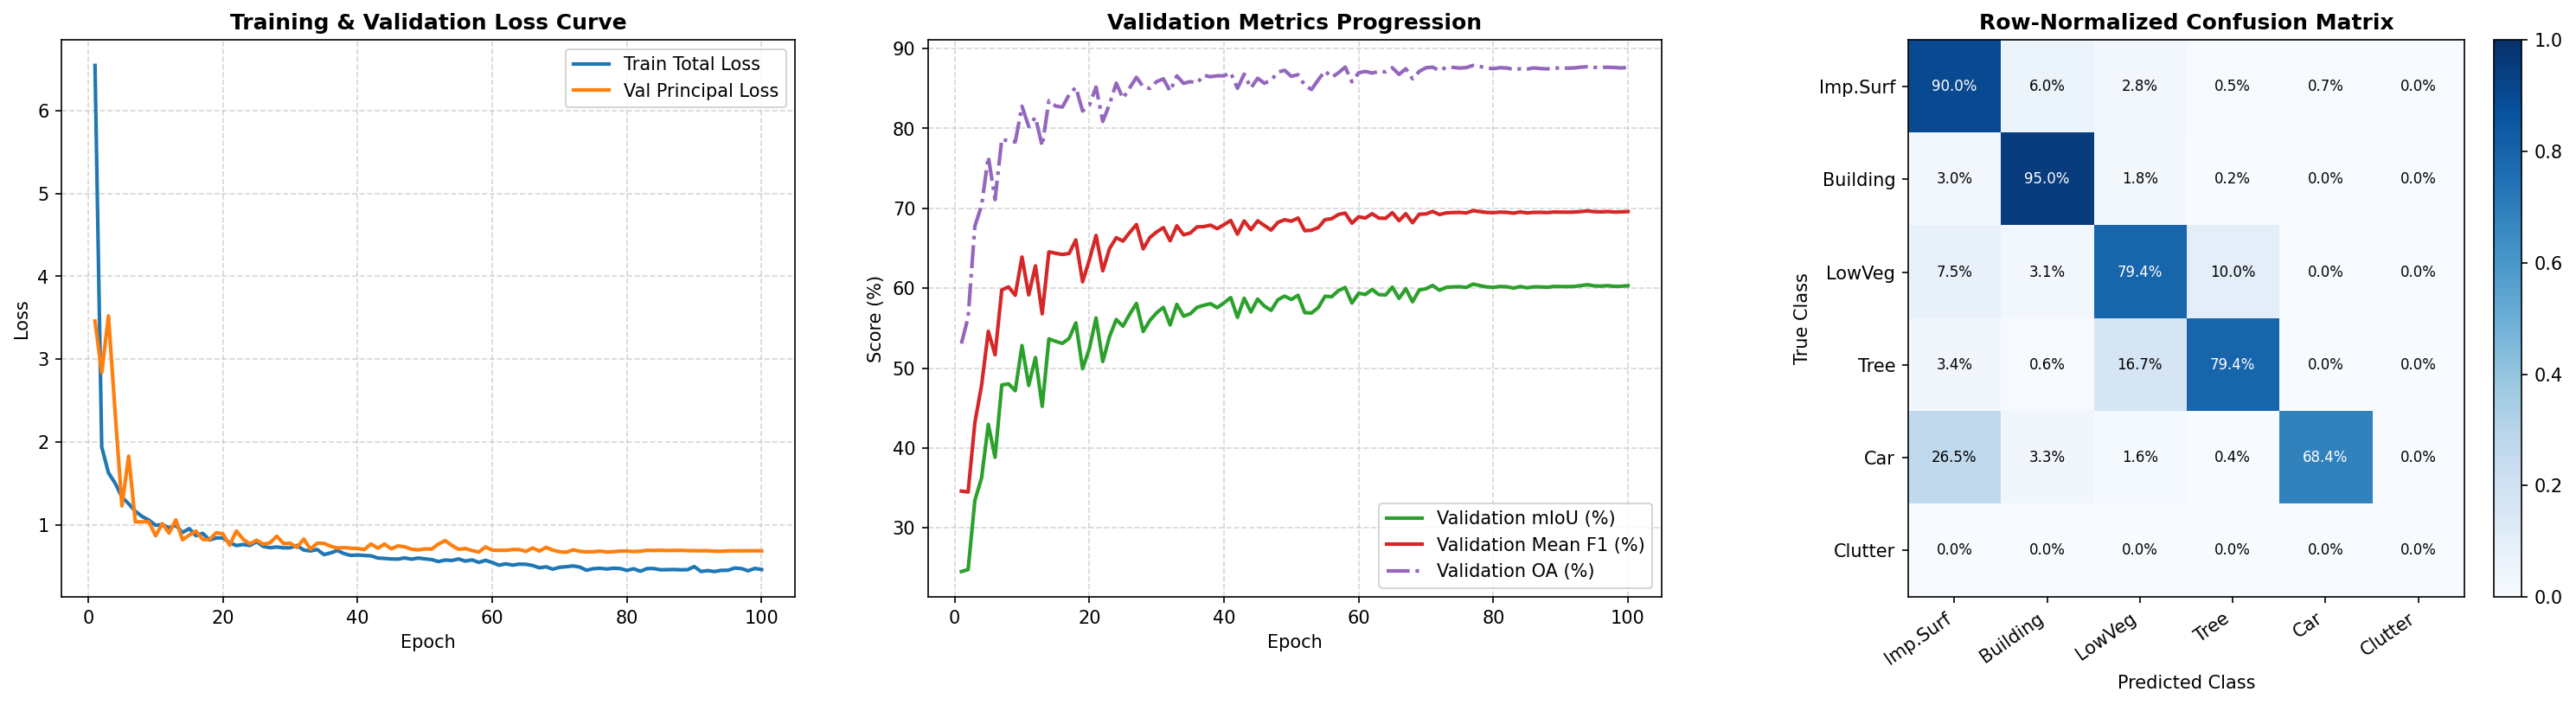

High-resolution evaluation plot saved to Google Drive: /content/drive/MyDrive/UNetFormer_ISPRS_Project/evaluation_curves_and_confusion_matrix.png


In [ ]:

import os
import json
import time
import numpy as np
import torch
import matplotlib.pyplot as plt

CLASS_NAMES = [
    "Impervious Surfaces",
    "Building",
    "Low Vegetation",
    "Tree",
    "Car",
    "Clutter / Background"
]

def run_comprehensive_evaluation(
    drive_dir: str = "/content/drive/MyDrive/UNetFormer_ISPRS_Project"
) -> None:
    """
    Load the best model checkpoint, compute detailed per-class metrics,
    measure inference speed (FPS / Latency), generate high-res plots,
    and output ready-to-copy Markdown tables for a GitHub README.
    """
    best_ckpt_path = os.path.join(drive_dir, "unetformer_best.pth")
    history_path = os.path.join(drive_dir, "training_history.json")

    if not os.path.exists(best_ckpt_path):
        raise FileNotFoundError(f"Best checkpoint not found at {best_ckpt_path}. Run training first.")

    # 1. Load Best Model Weights
    ckpt = torch.load(best_ckpt_path, map_location=device)
    model.load_state_dict(ckpt["model_state_dict"])
    model.eval()
    best_epoch = ckpt.get("epoch", -1)
    print(f"Loaded Best Model Checkpoint from Epoch {best_epoch} (Saved mIoU: {ckpt.get('best_miou', 0.0):.2f}%)\n")

    # 2. Accumulate Full Confusion Matrix on Validation Set
    evaluator = SegmentationMetrics(num_classes=NUM_CLASSES, device=device)
    evaluator.reset()

    with torch.no_grad():
        for batch in val_loader:
            images = batch["image"].to(device, non_blocking=True)
            masks = batch["mask"].to(device, non_blocking=True)
            with torch.amp.autocast(device_type="cuda", enabled=(device == "cuda")):
                logits = model(images)
            evaluator.update(logits, masks)

    cm = evaluator.confusion_matrix.float()
    eps = 1e-6
    tp = torch.diag(cm)
    fp = cm.sum(dim=0) - tp
    fn = cm.sum(dim=1) - tp

    iou = (tp / (tp + fp + fn + eps)) * 100.0
    f1 = ((2.0 * tp) / (2.0 * tp + fp + fn + eps)) * 100.0
    precision = (tp / (tp + fp + eps)) * 100.0
    recall = (tp / (tp + fn + eps)) * 100.0
    support_pct = (cm.sum(dim=1) / (cm.sum() + eps)) * 100.0

    # Mean metrics across all 6 classes and across the 5 foreground classes (excluding Clutter, standard ISPRS protocol)
    miou_all = iou.mean().item()
    mf1_all = f1.mean().item()
    miou_no_clutter = iou[:5].mean().item()
    mf1_no_clutter = f1[:5].mean().item()
    oa = (tp.sum() / (cm.sum() + eps)).item() * 100.0

    # 3. Hardware Complexity & Inference Speed (FPS) Benchmark at 512x512
    total_params = sum(p.numel() for p in model.parameters()) / 1e6
    trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad) / 1e6

    dummy_input = torch.randn(1, 3, 512, 512, device=device)
    # Warm-up GPU
    with torch.no_grad():
        for _ in range(20):
            _ = model(dummy_input)
    if device == "cuda":
        torch.cuda.synchronize()

    num_iters = 100
    t_start = time.perf_counter()
    with torch.no_grad():
        for _ in range(num_iters):
            _ = model(dummy_input)
    if device == "cuda":
        torch.cuda.synchronize()
    total_time = time.perf_counter() - t_start
    fps = num_iters / total_time
    latency_ms = (total_time / num_iters) * 1000.0

    # 4. Print Ready-to-Use GitHub Markdown Tables
    print("=" * 90)
    print("📋 COPY & PASTE THE FOLLOWING MARKDOWN TABLES DIRECTLY INTO YOUR GITHUB README.md:")
    print("=" * 90)
    print("\n### 1. Quantitative Per-Class Segmentation Results (ISPRS Validation Set)\n")
    print("| Class ID | Class Name | IoU (%) | F1-Score (%) | Precision (%) | Recall (%) | Pixel Share (%) |")
    print("|:---:|:---|:---:|:---:|:---:|:---:|:---:|")
    for idx, name in enumerate(CLASS_NAMES):
        print(
            f"| {idx} | **{name}** | {iou[idx].item():.2f} | {f1[idx].item():.2f} | "
            f"{precision[idx].item():.2f} | {recall[idx].item():.2f} | {support_pct[idx].item():.2f} |"
        )
    print(f"| - | **Mean (All 6 Classes)** | **{miou_all:.2f}** | **{mf1_all:.2f}** | "
          f"**{precision.mean().item():.2f}** | **{recall.mean().item():.2f}** | 100.00 |")
    print(f"| - | **Mean (Top 5 Foreground Classes)** | **{miou_no_clutter:.2f}** | **{mf1_no_clutter:.2f}** | "
          f"**{precision[:5].mean().item():.2f}** | **{recall[:5].mean().item():.2f}** | - |")

    print("\n### 2. Overall Performance & Computational Efficiency Summary\n")
    print("| Metric / Property | Value |")
    print("|:---|:---:|")
    print(f"| **Backbone Encoder** | ResNet-18 (ImageNet Pre-trained) |")
    print(f"| **Input Resolution** | 512 x 512 |")
    print(f"| **Total Parameters** | {total_params:.2f} M ({trainable_params:.2f} M Trainable) |")
    print(f"| **Overall Pixel Accuracy (OA)** | **{oa:.2f}%** |")
    print(f"| **mIoU (5 Foreground Classes / All 6)** | **{miou_no_clutter:.2f}%** / **{miou_all:.2f}%** |")
    print(f"| **Mean F1 (5 Foreground Classes / All 6)** | **{mf1_no_clutter:.2f}%** / **{mf1_all:.2f}%** |")
    print(f"| **Inference Speed (Batch Size = 1, FP32)** | **{fps:.1f} FPS** ({latency_ms:.2f} ms/image) |")
    print("=" * 90 + "\n")

    # 5. Plot Training Curves & Normalized Confusion Matrix
    fig, axes = plt.subplots(1, 3, figsize=(20, 5.5), dpi=150)

    if os.path.exists(history_path):
        with open(history_path, "r") as f:
            hist = json.load(f)
        epochs_range = range(1, len(hist["train_total_loss"]) + 1)

        # Subplot 1: Loss Curves
        axes[0].plot(epochs_range, hist["train_total_loss"], label="Train Total Loss", color="#1f77b4", linewidth=2)
        axes[0].plot(epochs_range, hist["val_loss"], label="Val Principal Loss", color="#ff7f0e", linewidth=2)
        axes[0].set_title("Training & Validation Loss Curve", fontsize=12, fontweight="bold")
        axes[0].set_xlabel("Epoch")
        axes[0].set_ylabel("Loss")
        axes[0].grid(True, linestyle="--", alpha=0.5)
        axes[0].legend()

        # Subplot 2: Validation Accuracy Metrics (mIoU, F1, OA)
        axes[1].plot(epochs_range, hist["val_mIoU"], label="Validation mIoU (%)", color="#2ca02c", linewidth=2)
        axes[1].plot(epochs_range, hist["val_mean_F1"], label="Validation Mean F1 (%)", color="#d62728", linewidth=2)
        axes[1].plot(epochs_range, hist["val_OA"], label="Validation OA (%)", color="#9467bd", linewidth=2, linestyle="-.")
        axes[1].set_title("Validation Metrics Progression", fontsize=12, fontweight="bold")
        axes[1].set_xlabel("Epoch")
        axes[1].set_ylabel("Score (%)")
        axes[1].grid(True, linestyle="--", alpha=0.5)
        axes[1].legend()

    # Subplot 3: Row-Normalized Confusion Matrix
    cm_np = cm.cpu().numpy()
    cm_norm = cm_np / (cm_np.sum(axis=1, keepdims=True) + 1e-6)
    im = axes[2].imshow(cm_norm, interpolation="nearest", cmap=plt.cm.Blues, vmin=0.0, vmax=1.0)
    axes[2].set_title("Row-Normalized Confusion Matrix", fontsize=12, fontweight="bold")
    plt.colorbar(im, ax=axes[2], fraction=0.046, pad=0.04)

    short_names = ["Imp.Surf", "Building", "LowVeg", "Tree", "Car", "Clutter"]
    tick_marks = np.arange(len(short_names))
    axes[2].set_xticks(tick_marks)
    axes[2].set_xticklabels(short_names, rotation=35, ha="right")
    axes[2].set_yticks(tick_marks)
    axes[2].set_yticklabels(short_names)
    axes[2].set_ylabel("True Class")
    axes[2].set_xlabel("Predicted Class")

    for i in range(len(short_names)):
        for j in range(len(short_names)):
            val = cm_norm[i, j]
            text_color = "white" if val > 0.5 else "black"
            axes[2].text(j, i, f"{val * 100:.1f}%", ha="center", va="center", color=text_color, fontsize=8)

    plt.tight_layout()
    eval_plot_path = os.path.join(drive_dir, "evaluation_curves_and_confusion_matrix.png")
    plt.savefig(eval_plot_path, dpi=300, bbox_inches="tight")
    plt.show()
    print(f"High-resolution evaluation plot saved to Google Drive: {eval_plot_path}")


# Run the comprehensive evaluation
run_comprehensive_evaluation()

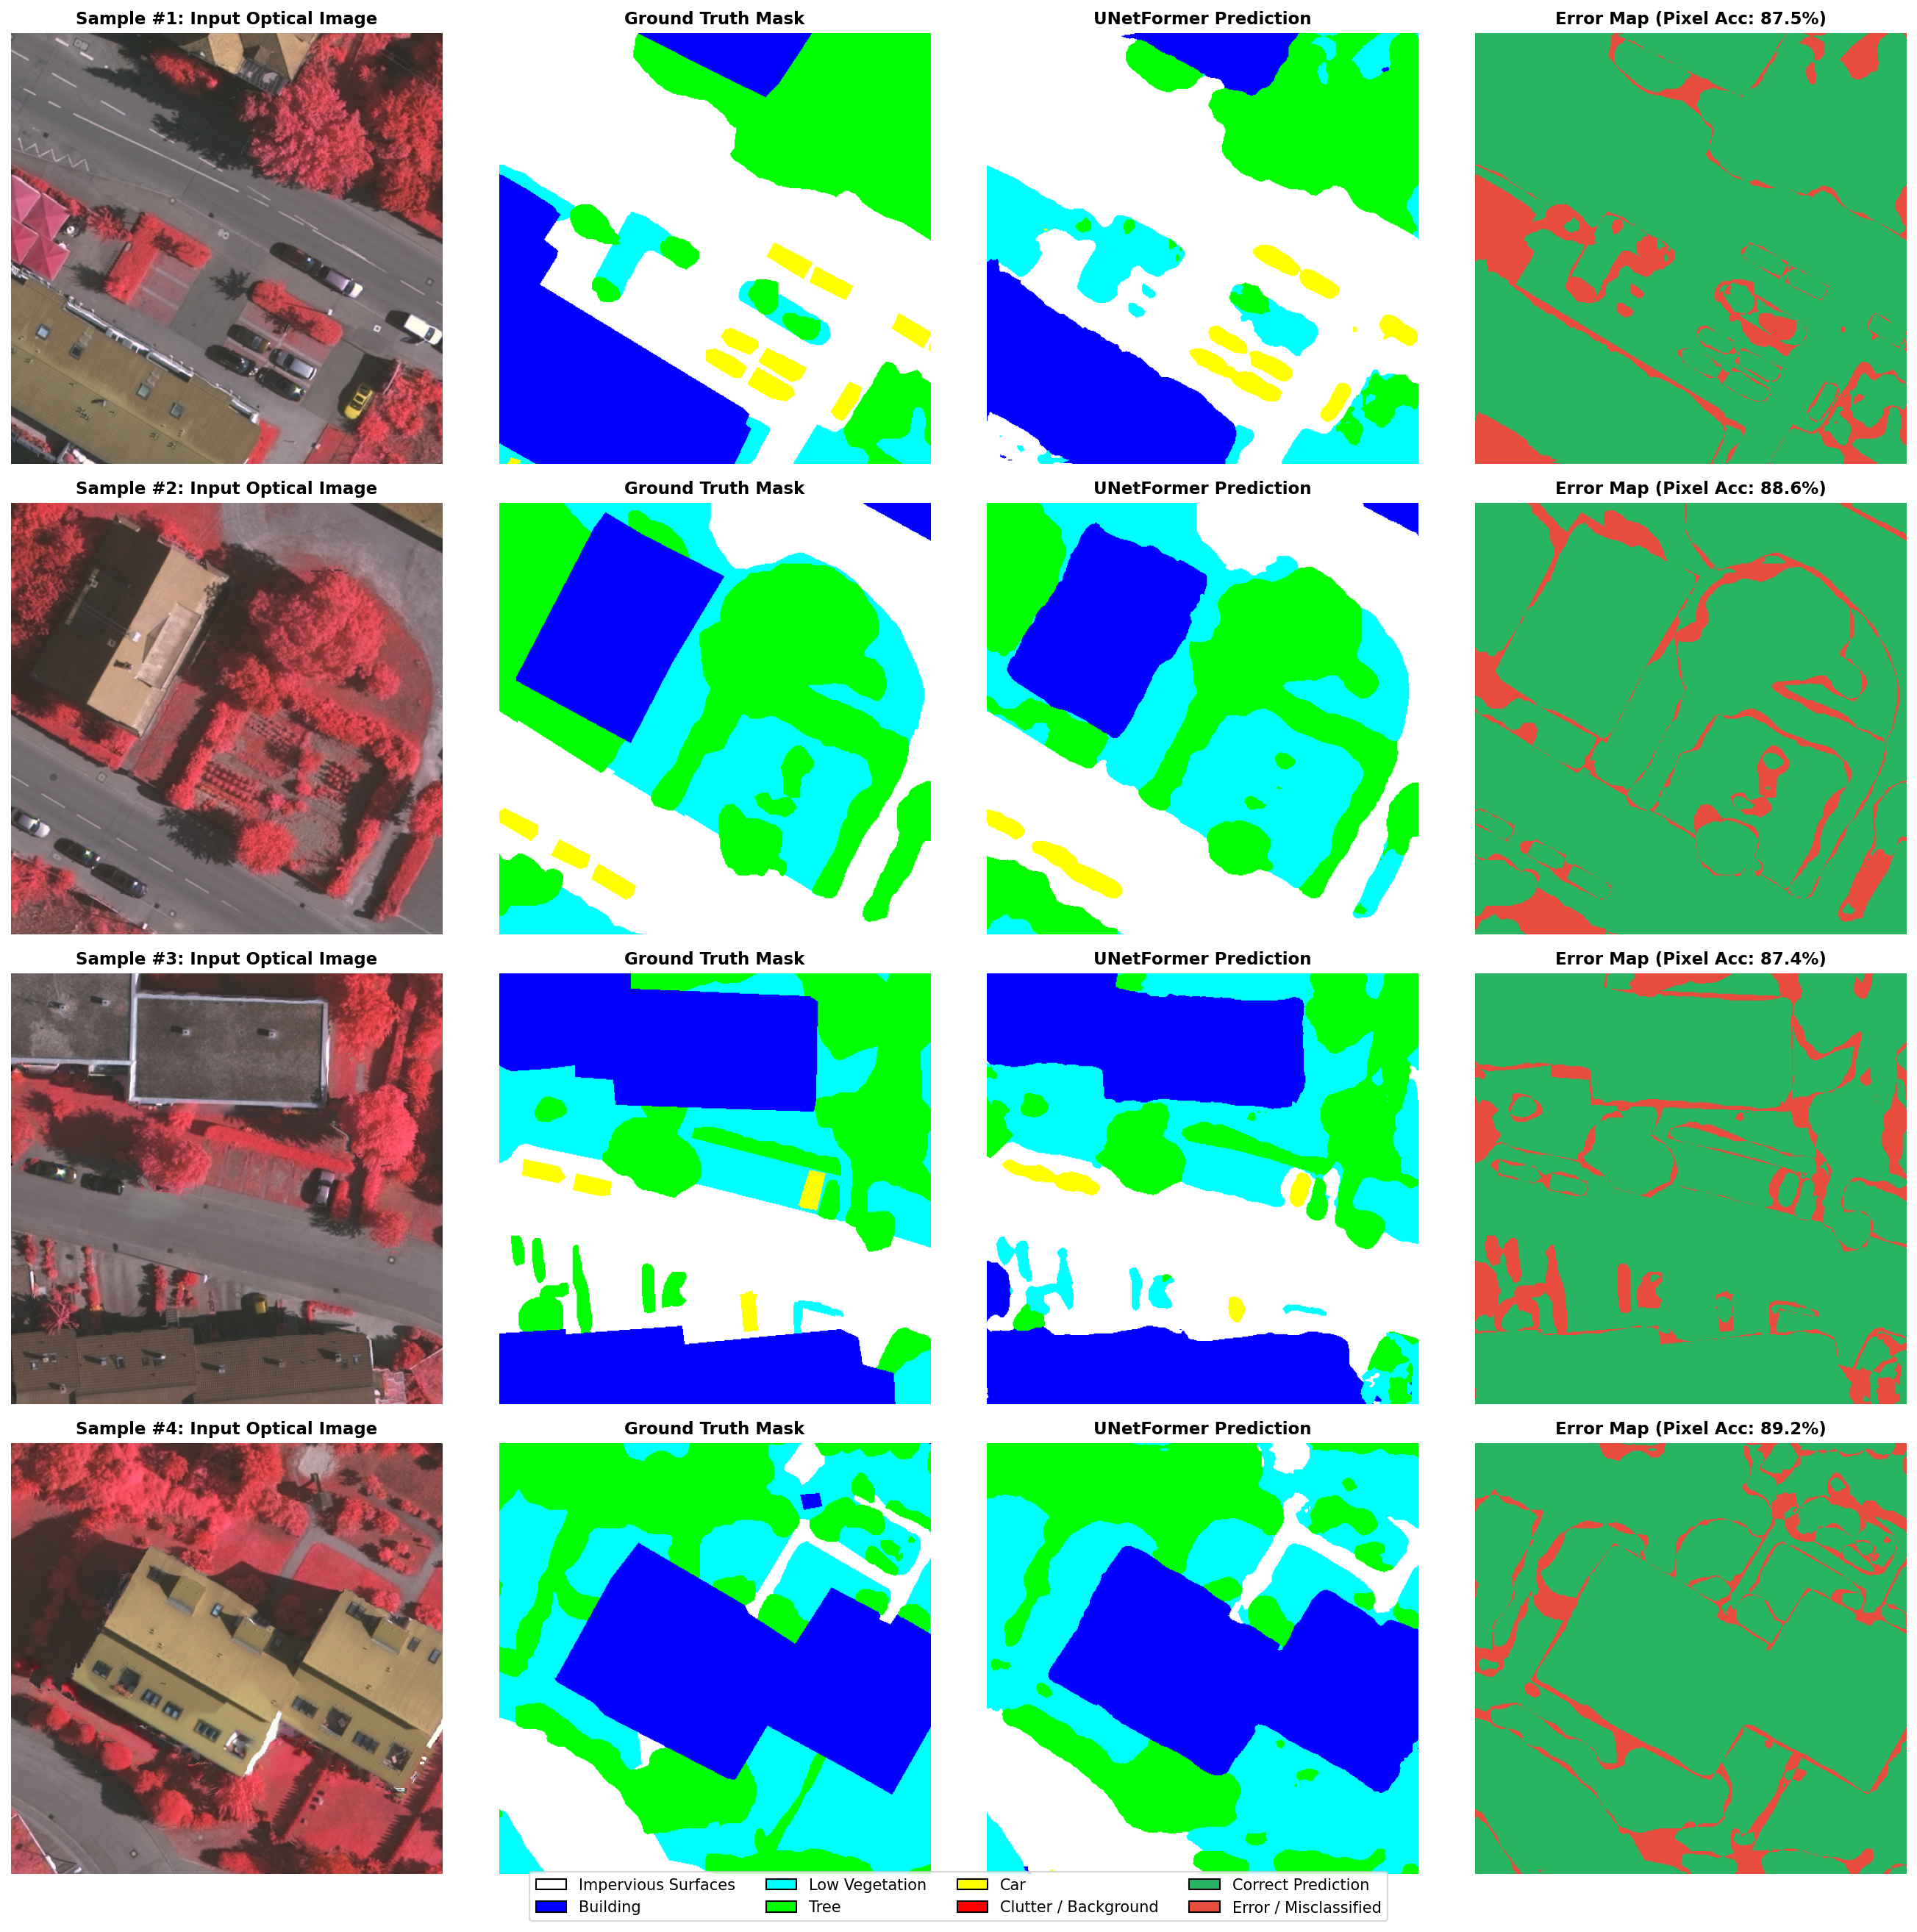

High-resolution visual comparison saved to Google Drive: /content/drive/MyDrive/UNetFormer_ISPRS_Project/qualitative_predictions_comparison.png


In [ ]:

import os
import numpy as np
import torch
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# Standard ISPRS RGB Palette for visualization
ISPRS_ID_TO_RGB = {
    0: (255, 255, 255),  # Impervious surfaces (White)
    1: (0, 0, 255),      # Building (Blue)
    2: (0, 255, 255),    # Low vegetation (Cyan)
    3: (0, 255, 0),      # Tree (Green)
    4: (255, 255, 0),    # Car (Yellow)
    5: (255, 0, 0)       # Clutter / Background (Red)
}

def decode_segmap_to_rgb(mask_2d: np.ndarray) -> np.ndarray:
    """Convert a 2D integer class mask [H, W] into a 3-channel RGB color image [H, W, 3]."""
    h, w = mask_2d.shape
    rgb_mask = np.zeros((h, w, 3), dtype=np.uint8)
    for class_id, color in ISPRS_ID_TO_RGB.items():
        rgb_mask[mask_2d == class_id] = color
    return rgb_mask


def denormalize_image(img_tensor: torch.Tensor) -> np.ndarray:
    """Invert ImageNet normalization on a [3, H, W] tensor and return uint8 [H, W, 3] RGB array."""
    mean = np.array([0.485, 0.456, 0.406], dtype=np.float32)
    std = np.array([0.229, 0.224, 0.225], dtype=np.float32)
    img_np = img_tensor.cpu().numpy().transpose(1, 2, 0)
    img_np = (img_np * std + mean) * 255.0
    return np.clip(img_np, 0, 255).astype(np.uint8)


def visualize_model_predictions(
    num_samples: int = 4,
    drive_dir: str = "/content/drive/MyDrive/UNetFormer_ISPRS_Project"
) -> None:
    """
    Visualize `num_samples` validation patches side-by-side:
    Column 1: Optical RGB Input
    Column 2: Ground Truth Semantic Mask
    Column 3: UNetFormer Predicted Mask
    Column 4: Correctness / Error Map (Green = Correct Pixel, Red = Misclassified Pixel)
    """
    model.eval()
    val_batch = next(iter(val_loader))
    images = val_batch["image"].to(device)
    masks = val_batch["mask"].to(device)

    num_samples = min(num_samples, images.size(0))

    with torch.no_grad():
        with torch.amp.autocast(device_type="cuda", enabled=(device == "cuda")):
            logits = model(images[:num_samples])
            preds = torch.argmax(logits, dim=1)

    fig, axes = plt.subplots(num_samples, 4, figsize=(18, 4.3 * num_samples), dpi=150)
    if num_samples == 1:
        axes = np.expand_dims(axes, axis=0)

    for i in range(num_samples):
        img_rgb = denormalize_image(images[i])
        gt_mask = masks[i].cpu().numpy()
        pred_mask = preds[i].cpu().numpy()

        gt_rgb = decode_segmap_to_rgb(gt_mask)
        pred_rgb = decode_segmap_to_rgb(pred_mask)

        # Compute Pixel Accuracy for this specific patch & create Green/Red Error Map
        correct_mask = (gt_mask == pred_mask)
        patch_acc = correct_mask.mean() * 100.0
        error_map = np.zeros_like(gt_rgb)
        error_map[correct_mask] = (40, 180, 99)     # Soft Green for correct pixels
        error_map[~correct_mask] = (231, 76, 60)    # Crimson Red for misclassified pixels

        # Plot 4 columns
        axes[i, 0].imshow(img_rgb)
        axes[i, 0].set_title(f"Sample #{i+1}: Input Optical Image", fontsize=11, fontweight="bold")
        axes[i, 0].axis("off")

        axes[i, 1].imshow(gt_rgb)
        axes[i, 1].set_title("Ground Truth Mask", fontsize=11, fontweight="bold")
        axes[i, 1].axis("off")

        axes[i, 2].imshow(pred_rgb)
        axes[i, 2].set_title("UNetFormer Prediction", fontsize=11, fontweight="bold")
        axes[i, 2].axis("off")

        axes[i, 3].imshow(error_map)
        axes[i, 3].set_title(f"Error Map (Pixel Acc: {patch_acc:.1f}%)", fontsize=11, fontweight="bold")
        axes[i, 3].axis("off")

    # Add unified color legend at the bottom of the figure
    legend_patches = [
        mpatches.Patch(facecolor=np.array(ISPRS_ID_TO_RGB[k]) / 255.0, edgecolor="black", label=CLASS_NAMES[k])
        for k in range(NUM_CLASSES)
    ] + [
        mpatches.Patch(facecolor=np.array([40, 180, 99]) / 255.0, edgecolor="black", label="Correct Prediction"),
        mpatches.Patch(facecolor=np.array([231, 76, 60]) / 255.0, edgecolor="black", label="Error / Misclassified")
    ]

    fig.legend(
        handles=legend_patches,
        loc="lower center",
        ncol=4,
        fontsize=10,
        frameon=True,
        bbox_to_anchor=(0.5, -0.02)
    )

    plt.tight_layout()
    vis_save_path = os.path.join(drive_dir, "qualitative_predictions_comparison.png")
    plt.savefig(vis_save_path, dpi=300, bbox_inches="tight")
    plt.show()
    print(f"High-resolution visual comparison saved to Google Drive: {vis_save_path}")


# Generate and save the visual comparison
visualize_model_predictions(num_samples=4)